# TA-03: Data-Driven Monte Carlo Simulation
**Praktikum Pemodelan dan Simulasi**

Nama : Wifa Saputra Mahendra  
NIM  : 301240063

**Studi kasus:** Simulasi Peluang Target Profit Kanal Penjualan Online vs Toko Fisik  
**Dataset:** Retail Store Sales: Dirty for Data Cleaning (Kaggle), file `retail_store_sales.csv`

**Pertanyaan simulasi:** Berapa probabilitas masing-masing kanal penjualan (toko fisik dan online) mencapai target profit bulan depan, dan kanal mana yang risikonya lebih kecil?

Alur notebook: (1) eksplorasi dan pembersihan data, (2) mengambil parameter dari data asli, (3) simulasi Monte Carlo 5.000 skenario, (4) analisis risiko.

## Langkah 0: Import Library dan Mengatur Seed

In [1]:
import numpy as np                # perhitungan numerik dan pembangkit angka acak
import pandas as pd               # membaca dan mengolah data CSV
import matplotlib.pyplot as plt   # membuat grafik

np.random.seed(301240063)         # seed memakai NIM supaya hasil simulasi konsisten dan bisa diulang
print("Library siap dipakai.")

Library siap dipakai.


## Langkah 1: Eksplorasi Data Kaggle
### 1.1 Memuat Data

In [2]:
df_raw = pd.read_csv('retail_store_sales.csv')   # baca file CSV hasil unduhan dari Kaggle

print("Jumlah baris :", len(df_raw))
print("Kolom        :", list(df_raw.columns))
print("\nJumlah nilai kosong per kolom:")
print(df_raw.isna().sum().to_string())
print("\nJumlah transaksi per kanal:")
print(df_raw['Location'].value_counts().to_string())

Jumlah baris : 12575
Kolom        : ['Transaction ID', 'Customer ID', 'Category', 'Item', 'Price Per Unit', 'Quantity', 'Total Spent', 'Payment Method', 'Location', 'Transaction Date', 'Discount Applied']

Jumlah nilai kosong per kolom:
Transaction ID         0
Customer ID            0
Category               0
Item                1213
Price Per Unit       609
Quantity             604
Total Spent          604
Payment Method         0
Location               0
Transaction Date       0
Discount Applied    4199

Jumlah transaksi per kanal:
Location
Online      6354
In-store    6221


### 1.2 Pembersihan Data (Data Cleaning)
Aturan pembersihan yang dipakai:
1. **Harga per unit kosong** dipulihkan dari `Total Spent / Quantity`, karena kedua kolom itu terisi.
2. **Baris yang `Total Spent`-nya kosong** dihapus, karena nilai transaksinya tidak bisa dipulihkan (kolom `Quantity` juga kosong di baris itu).
3. **Bulan terakhir (Januari 2025) dibuang** karena data hanya sampai tanggal 18, sehingga belum satu bulan penuh.
4. Kolom `Item` dan `Discount Applied` punya banyak nilai kosong, tetapi tidak dipakai dalam simulasi ini sehingga dibiarkan.

In [3]:
df = df_raw.copy()

# 1) pulihkan harga per unit yang kosong: harga = total / jumlah
mask_harga = df['Price Per Unit'].isna() & df['Quantity'].notna() & df['Total Spent'].notna()
df.loc[mask_harga, 'Price Per Unit'] = df.loc[mask_harga, 'Total Spent'] / df.loc[mask_harga, 'Quantity']
print("Harga per unit yang dipulihkan :", mask_harga.sum())

# 2) hapus baris yang Total Spent-nya kosong (tidak bisa dipulihkan)
sebelum = len(df)
df = df.dropna(subset=['Total Spent'])
print("Baris yang dihapus             :", sebelum - len(df))

# 3) ubah kolom tanggal ke tipe tanggal, lalu buang bulan terakhir yang belum penuh
df['Transaction Date'] = pd.to_datetime(df['Transaction Date'])
df = df[df['Transaction Date'] < '2025-01-01']
print("Rentang tanggal data bersih    :", df['Transaction Date'].min().date(), "sampai", df['Transaction Date'].max().date())
print("Jumlah baris data bersih       :", len(df))

# cek outlier dengan aturan IQR (hanya dilihat, tidak dihapus)
q1, q3 = df['Total Spent'].quantile([0.25, 0.75])
batas_atas = q3 + 1.5 * (q3 - q1)
print(f"\nOutlier nilai transaksi (IQR) : {(df['Total Spent'] > batas_atas).sum()} baris (batas atas {batas_atas:.1f})")
print(f"Nilai transaksi min/max       : {df['Total Spent'].min()} / {df['Total Spent'].max()}  -> masih masuk akal, jadi outlier tidak dihapus")

Harga per unit yang dipulihkan : 609
Baris yang dihapus             : 604
Rentang tanggal data bersih    : 2022-01-01 sampai 2024-12-31
Jumlah baris data bersih       : 11769

Outlier nilai transaksi (IQR) : 59 baris (batas atas 403.5)
Nilai transaksi min/max       : 5.0 / 410.0  -> masih masuk akal, jadi outlier tidak dihapus


### 1.3 Mengambil Parameter dan Mengidentifikasi Distribusi
Karena soal meminta simulasi berdasarkan *Unit Price* dan *Quantity*, variabel acak yang dipakai untuk tiap kanal adalah:
- **Jumlah transaksi per hari** (hari tanpa transaksi dihitung 0).
- **Harga per unit** (`Price Per Unit`).
- **Jumlah barang per transaksi** (`Quantity`), yang diuji kecocokannya dengan distribusi Uniform diskrit 1 sampai 10 memakai uji chi-square.

Dicek juga korelasi antara harga dan jumlah, karena simulasi mengasumsikan keduanya saling bebas.

In [4]:
kanal_list = ['In-store', 'Online']
semua_hari = pd.date_range(df['Transaction Date'].min(), df['Transaction Date'].max())   # semua hari, termasuk yang sepi
params = {}

def chi_square_uniform(seri):
    """Uji chi-square terhadap distribusi Uniform diskrit (semua nilai punya peluang sama)."""
    teramati = seri.value_counts().sort_index().values
    diharapkan = len(seri) / len(teramati)
    return ((teramati - diharapkan) ** 2 / diharapkan).sum(), len(teramati) - 1

for kanal in kanal_list:
    d = df[df['Location'] == kanal]
    harian = d.groupby('Transaction Date').size().reindex(semua_hari, fill_value=0)   # transaksi per hari
    harga, jumlah = d['Price Per Unit'], d['Quantity']
    chi_q, db_q = chi_square_uniform(jumlah)
    chi_h, db_h = chi_square_uniform(harga)
    params[kanal] = {'trx_per_hari': harian.mean()}
    print(f"[{kanal}]")
    print(f"  Transaksi per hari : rata-rata {harian.mean():.3f} | varians {harian.var():.3f}  (mirip -> cocok Poisson)")
    print(f"  Harga per unit     : rata-rata {harga.mean():.2f} | std {harga.std():.2f} | skewness {harga.skew():.2f} | {harga.nunique()} nilai berbeda")
    print(f"  Jumlah per transaksi: rata-rata {jumlah.mean():.3f} | std {jumlah.std():.3f} | min {jumlah.min():.0f} | max {jumlah.max():.0f}")
    print(f"  Chi-square Quantity vs Uniform(1..10): {chi_q:.2f} (db={db_q}, kritis 5% = 16.92) -> {'cocok' if chi_q < 16.92 else 'tidak cocok'}")
    print(f"  Chi-square Harga vs Uniform ({db_h + 1} nilai): {chi_h:.2f} (db={db_h}, kritis 5% = 36.42) -> {'cocok' if chi_h < 36.42 else 'tidak cocok'}")
    print(f"  Korelasi harga dan jumlah: {harga.corr(jumlah):.4f}  (mendekati 0 -> saling bebas)")

[In-store]
  Transaksi per hari : rata-rata 5.286 | varians 5.810  (mirip -> cocok Poisson)
  Harga per unit     : rata-rata 23.28 | std 10.79 | skewness -0.01 | 25 nilai berbeda
  Jumlah per transaksi: rata-rata 5.521 | std 2.869 | min 1 | max 10
  Chi-square Quantity vs Uniform(1..10): 10.27 (db=9, kritis 5% = 16.92) -> cocok
  Chi-square Harga vs Uniform (25 nilai): 241.96 (db=24, kritis 5% = 36.42) -> tidak cocok
  Korelasi harga dan jumlah: 0.0151  (mendekati 0 -> saling bebas)
[Online]
  Transaksi per hari : rata-rata 5.453 | varians 5.760  (mirip -> cocok Poisson)
  Harga per unit     : rata-rata 23.42 | std 10.69 | skewness -0.05 | 25 nilai berbeda
  Jumlah per transaksi: rata-rata 5.556 | std 2.847 | min 1 | max 10
  Chi-square Quantity vs Uniform(1..10): 13.43 (db=9, kritis 5% = 16.92) -> cocok
  Chi-square Harga vs Uniform (25 nilai): 251.59 (db=24, kritis 5% = 36.42) -> tidak cocok
  Korelasi harga dan jumlah: 0.0088  (mendekati 0 -> saling bebas)


### 1.4 Histogram Data Asli
Histogram harga per unit dan jumlah per transaksi dipakai untuk melihat bentuk distribusinya.

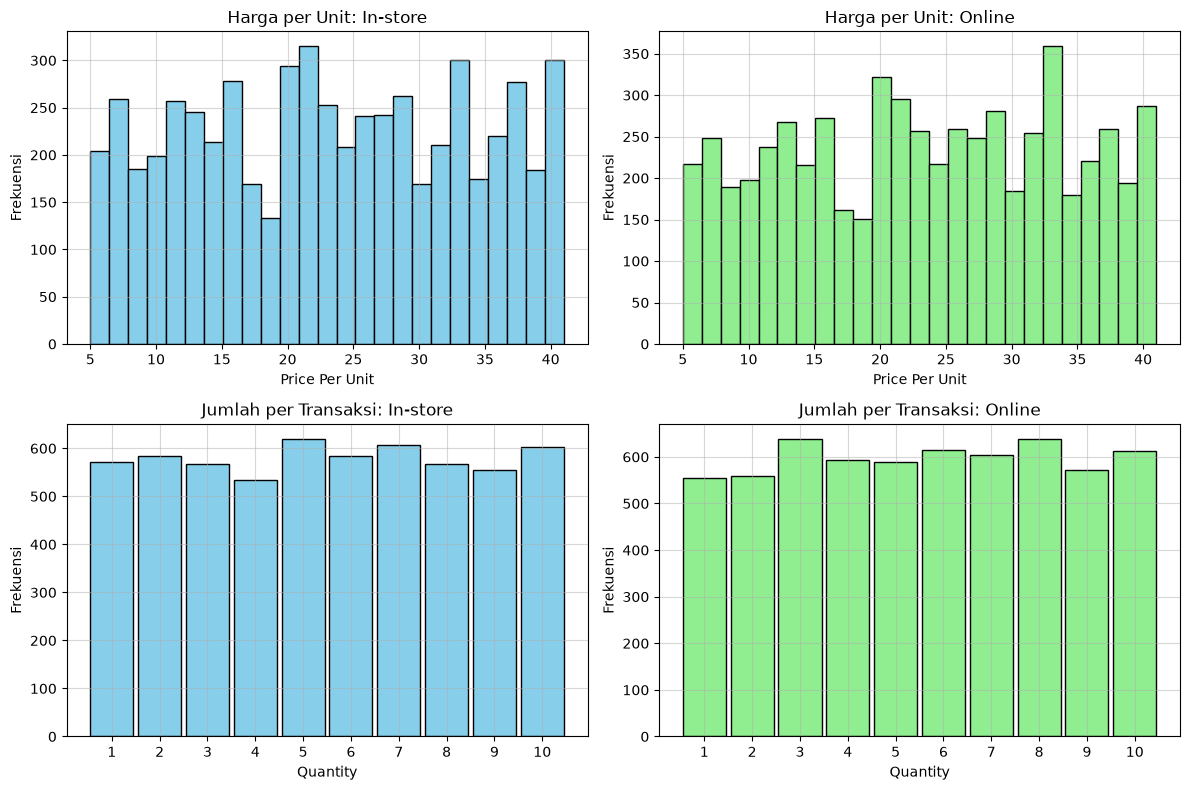

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
warna = {'In-store': 'skyblue', 'Online': 'lightgreen'}

for j, kanal in enumerate(kanal_list):
    d = df[df['Location'] == kanal]
    # baris atas: harga per unit
    axes[0, j].hist(d['Price Per Unit'], bins=25, color=warna[kanal], edgecolor='black')
    axes[0, j].set_title(f'Harga per Unit: {kanal}')
    axes[0, j].set_xlabel('Price Per Unit')
    # baris bawah: jumlah barang per transaksi
    axes[1, j].hist(d['Quantity'], bins=np.arange(0.5, 11.5, 1), color=warna[kanal], edgecolor='black', rwidth=0.9)
    axes[1, j].set_title(f'Jumlah per Transaksi: {kanal}')
    axes[1, j].set_xlabel('Quantity')
    axes[1, j].set_xticks(range(1, 11))
    for i in (0, 1):
        axes[i, j].set_ylabel('Frekuensi')
        axes[i, j].grid(True, alpha=0.5)

plt.tight_layout()
plt.savefig('histogram_data_asli.png', dpi=150)   # simpan sebagai PNG
plt.show()

## Langkah 2: Membangun Simulasi Monte Carlo
**Model:** profit bulanan suatu kanal = margin x jumlah dari (harga x jumlah barang) untuk semua transaksi dalam satu bulan.

- **Jumlah transaksi** dalam satu bulan diambil dari distribusi **Poisson** (rata-rata = transaksi per hari x 30,44 hari, yaitu rata-rata panjang satu bulan).
- **Harga per unit** diambil acak dari data asli (resampling). Harganya berupa 25 nilai diskret yang sebarannya tidak rata sempurna (uji chi-square menolak Uniform), sehingga distribusi bawaan kurang cocok.
- **Jumlah barang** juga diambil acak dari data asli. Hasil uji chi-square dan histogram menunjukkan jumlahnya mengikuti **Uniform diskrit 1 sampai 10**, sehingga resampling memberi hasil yang sama dengan Uniform tetapi tetap setia pada data.
- Nilai satu transaksi = harga x jumlah. Harga dan jumlah dianggap saling bebas (korelasinya mendekati 0).
- Dataset tidak punya kolom profit, jadi dipakai **asumsi margin 20%** dari total penjualan.
- Jumlah skenario: **5.000**.

In [6]:
n_iter = 5000       # jumlah skenario simulasi
hari = 365.25 / 12  # periode satu bulan = rata-rata panjang bulan kalender (sekitar 30,44 hari)
margin = 0.20       # ASUMSI: profit = 20% dari total penjualan

pendapatan_sim = {}   # menyimpan hasil pendapatan bulanan simulasi tiap kanal

for kanal in kanal_list:
    harga_asli = df[df['Location'] == kanal]['Price Per Unit'].values
    jumlah_asli = df[df['Location'] == kanal]['Quantity'].values
    lam_bulan = params[kanal]['trx_per_hari'] * hari           # rata-rata transaksi dalam satu bulan
    jumlah_trx = np.random.poisson(lam_bulan, n_iter)          # jumlah transaksi tiap skenario
    pendapatan = np.empty(n_iter)
    for i, n in enumerate(jumlah_trx):
        harga = np.random.choice(harga_asli, size=n)           # harga satuan diambil acak dari data asli
        jumlah = np.random.choice(jumlah_asli, size=n)         # jumlah barang diambil acak dari data asli
        pendapatan[i] = (harga * jumlah).sum()                 # nilai transaksi = harga x jumlah, lalu dijumlahkan
    pendapatan_sim[kanal] = pendapatan

profit_sim = {k: v * margin for k, v in pendapatan_sim.items()}   # ubah pendapatan menjadi profit

# VALIDASI: bandingkan hasil simulasi dengan data historis (pendapatan per bulan kalender)
bulanan = df.groupby([df['Transaction Date'].dt.to_period('M'), 'Location'])['Total Spent'].sum().unstack()
print(f"Jumlah bulan historis: {len(bulanan)}\n")
for kanal in kanal_list:
    print(f"[{kanal}] pendapatan bulanan")
    print(f"  Historis : rata-rata {bulanan[kanal].mean():9.1f} | std {bulanan[kanal].std():7.1f}")
    print(f"  Simulasi : rata-rata {pendapatan_sim[kanal].mean():9.1f} | std {pendapatan_sim[kanal].std():7.1f}")

Jumlah bulan historis: 36

[In-store] pendapatan bulanan
  Historis : rata-rata   20757.0 | std  2524.2
  Simulasi : rata-rata   20676.7 | std  2001.3
[Online] pendapatan bulanan
  Historis : rata-rata   21646.4 | std  2544.7
  Simulasi : rata-rata   21577.5 | std  2078.4


## Langkah 3: Analisis Risiko dan Kesimpulan
**Target profit** ditetapkan sama untuk kedua kanal supaya perbandingannya adil: **rata-rata profit bulanan historis kedua kanal, dinaikkan 5%**.

$$P(\text{Capai Target}) = \frac{\text{Jumlah Skenario dengan Profit} \geq \text{Target}}{\text{Total Skenario}}$$

Rata-rata profit bulanan historis : 4240.3
Target profit bulan depan (+5%)   : 4452.4

[In-store]
  Rata-rata profit simulasi : 4135.3
  Rentang 95%               : 3387.1 sampai 4944.4
  P(profit >= target)       : 0.2084  (20.8%)
  P(profit < target)        : 0.7916  (79.2%)
[Online]
  Rata-rata profit simulasi : 4315.5
  Rentang 95%               : 3537.4 sampai 5146.2
  P(profit >= target)       : 0.3674  (36.7%)
  P(profit < target)        : 0.6326  (63.3%)


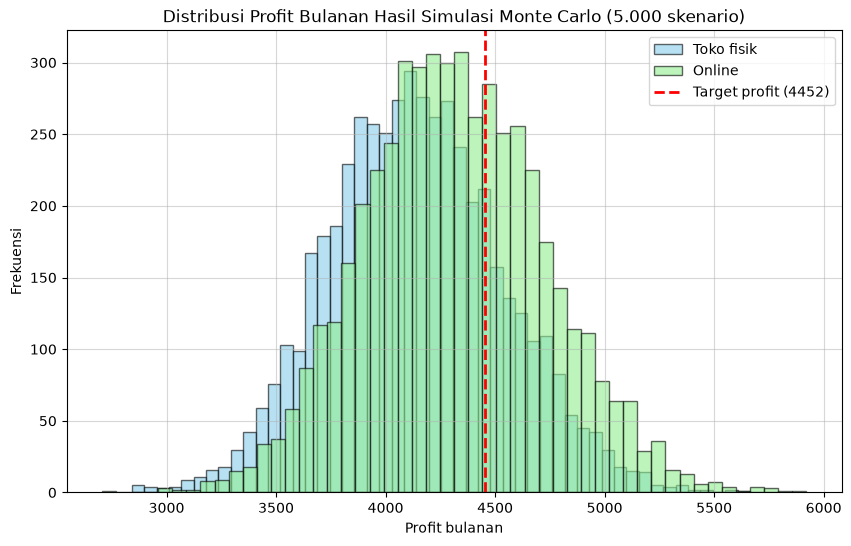

In [7]:
# target profit: rata-rata profit bulanan historis gabungan kedua kanal, dinaikkan 5%
profit_historis = (bulanan * margin).mean().mean()
target = profit_historis * 1.05
print(f"Rata-rata profit bulanan historis : {profit_historis:.1f}")
print(f"Target profit bulan depan (+5%)   : {target:.1f}\n")

# hitung probabilitas tiap kanal: skenario yang memenuhi kondisi / total skenario
hasil_prob = {}
for kanal in kanal_list:
    p = profit_sim[kanal]
    hasil_prob[kanal] = (p >= target).sum() / n_iter
    low, high = np.percentile(p, [2.5, 97.5])
    print(f"[{kanal}]")
    print(f"  Rata-rata profit simulasi : {p.mean():.1f}")
    print(f"  Rentang 95%               : {low:.1f} sampai {high:.1f}")
    print(f"  P(profit >= target)       : {hasil_prob[kanal]:.4f}  ({hasil_prob[kanal]*100:.1f}%)")
    print(f"  P(profit < target)        : {1 - hasil_prob[kanal]:.4f}  ({(1 - hasil_prob[kanal])*100:.1f}%)")

# histogram hasil simulasi dengan garis batas target
plt.figure(figsize=(10, 6))
plt.hist(profit_sim['In-store'], bins=50, alpha=0.6, color='skyblue', edgecolor='black', label='Toko fisik')
plt.hist(profit_sim['Online'], bins=50, alpha=0.6, color='lightgreen', edgecolor='black', label='Online')
plt.axvline(target, color='red', linestyle='--', linewidth=2, label=f'Target profit ({target:.0f})')   # garis batas risiko
plt.title('Distribusi Profit Bulanan Hasil Simulasi Monte Carlo (5.000 skenario)')
plt.xlabel('Profit bulanan')
plt.ylabel('Frekuensi')
plt.legend()
plt.grid(True, alpha=0.5)
plt.savefig('histogram_hasil_simulasi.png', dpi=150)
plt.show()

## Analisis Singkat dan Kesimpulan

**1. Data dan pembersihan.** Dataset awal berisi 12.575 baris. Sebanyak 609 harga per unit yang kosong berhasil dipulihkan dari `Total Spent / Quantity`, 604 baris yang nilai transaksinya tidak bisa dipulihkan dihapus, dan Januari 2025 dibuang karena belum satu bulan penuh. Hasilnya 11.769 baris bersih untuk 36 bulan penuh (Januari 2022 sampai Desember 2024). Nilai transaksi berkisar 5 sampai 410, yang masih wajar, sehingga outlier IQR (59 baris) tidak dihapus.

**2. Parameter dan distribusi dari data.**
- **Jumlah transaksi per hari:** rata-rata 5,29 (varians 5,81) untuk toko fisik dan 5,45 (varians 5,76) untuk online. Varians yang mendekati rata-rata menunjukkan distribusi **Poisson** cocok.
- **Harga per unit:** 25 nilai berbeda antara 5 dan 41, dengan rata-rata sekitar 23,3 di kedua kanal. Uji chi-square (241,96 dan 251,59, jauh di atas batas 36,42) menunjukkan harga tidak mengikuti Uniform sempurna, sehingga diambil langsung dari data asli.
- **Jumlah per transaksi:** bernilai 1 sampai 10 dengan rata-rata sekitar 5,5. Uji chi-square 10,27 (toko fisik) dan 13,43 (online) masih di bawah batas 16,92, jadi distribusinya **Uniform diskrit 1 sampai 10**.
- **Keterkaitan harga dan jumlah:** korelasinya hanya 0,015 dan 0,009, sehingga keduanya dapat dianggap saling bebas dan boleh dibangkitkan terpisah.

**3. Hasil simulasi (5.000 skenario).** Target profit bulan depan adalah 4.452 (rata-rata profit historis dinaikkan 5%).

| Kanal | Rata-rata profit simulasi | Rentang 95% | Peluang mencapai target |
|---|---|---|---|
| Toko fisik | 4.135 | 3.387 sampai 4.944 | 20,8% |
| Online | 4.316 | 3.537 sampai 5.146 | 36,7% |

Peluang kedua kanal di bawah 50% karena targetnya sengaja ditetapkan 5% di atas rata-rata historis. Kanal online punya peluang lebih besar karena rata-rata penjualan bulanannya sekitar 4% lebih tinggi (21.646 dibanding 20.757 pada data historis). Peluang ini tidak bergantung pada angka margin 20%, karena target juga dihitung dari margin yang sama.

**4. Validasi dan keterbatasan.** Rata-rata pendapatan bulanan hasil simulasi sangat dekat dengan data historis (20.677 dibanding 20.757 untuk toko fisik, dan 21.578 dibanding 21.646 untuk online, selisih kurang dari 0,5%). Namun, simpangan baku simulasi (sekitar 2.000 dan 2.080) lebih kecil daripada data historis (sekitar 2.520 dan 2.540). Artinya model mungkin sedikit meremehkan naik turunnya penjualan antarbulan, misalnya karena pola musiman yang tidak dimodelkan, sehingga risiko sebenarnya bisa sedikit lebih lebar. Selain itu, margin 20% adalah asumsi karena dataset tidak punya kolom profit, dan dataset ini bersifat sintetis sehingga kedua kanal hampir identik.

**5. Kesimpulan.** Kanal online sedikit lebih menjanjikan untuk mencapai target (36,7% dibanding 20,8%) dan risiko tidak mencapai targetnya lebih kecil (63,3% dibanding 79,2%). Namun selisih antar kanal kecil, jadi keputusan sebaiknya tidak hanya bergantung pada simulasi ini.
